# PpIA — Actividad fundamental 2
**Uso de Pandas, NumPy y Matplotlib**

| Integrante | Matrícula |
|---|---|
| NOMBRE COMPLETO 1 | MATRÍCULA 1 |
| NOMBRE COMPLETO 2 | MATRÍCULA 2 |

Este notebook resuelve los dos ejercicios de la actividad: el análisis del *Wine Quality Dataset* (UCI, vino tinto) y el de los *Palmer Penguins*.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.dpi"] = 100
pd.set_option("display.width", 120)

---
# Ejercicio 1 — Wine Quality Dataset (UCI)

## Ejercicio 1.1 — Limpieza y manipulación con Pandas
**Nombre:** NOMBRE COMPLETO · **Matrícula:** MATRÍCULA

**Lógica:** cargo el CSV directo desde la URL de UCI (el separador es `;`). Reviso su forma, las primeras filas y `describe()`. Cuento los nulos por columna y uso `dropna()` para quitarlos. Con una comparación vectorizada creo `is_good` (1 si `quality > 6`, si no 0). Al final aplico una máscara booleana para quedarme con los vinos de `alcohol > 11`.

In [2]:
url_vino = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
df = pd.read_csv(url_vino, sep=";")
print("¡Dataset cargado con éxito!", df.shape)
df.head()

¡Dataset cargado con éxito! (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [3]:
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [4]:
nulos = df.isnull().sum()
print("Valores nulos por columna:\n", nulos)
print("\nTotal de nulos:", nulos.sum())

filas_antes = len(df)
df = df.dropna()
print(f"Filas antes: {filas_antes} | después de eliminar nulos: {len(df)}")

Valores nulos por columna:
 fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
Length: 12, dtype: int64

Total de nulos: 0
Filas antes: 1599 | después de eliminar nulos: 1599


In [5]:
df["is_good"] = (df["quality"] > 6).astype(int)
print(df["is_good"].value_counts().rename({0: "no (≤6)", 1: "sí (>6)"}))
df[["quality", "is_good"]].head(10)

is_good
no (≤6)    1382
sí (>6)     217
Name: count, Length: 2, dtype: int64


,quality,is_good
0,5,0
1,5,0
2,5,0
3,6,0
4,5,0
5,5,0
6,5,0
7,7,1
8,7,1
9,5,0


In [6]:
alto_alcohol = df[df["alcohol"] > 11]
print(f"Vinos con alcohol > 11%: {len(alto_alcohol)} de {len(df)}")
alto_alcohol.head()

Vinos con alcohol > 11%: 408 de 1599


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,is_good
45,4.6,0.52,0.15,2.1,0.054,8.0,65.0,0.9934,3.90,0.56,13.1,4,0
95,4.7,0.60,0.17,2.3,0.058,17.0,106.0,0.9932,3.85,0.60,12.9,6,0
131,5.6,0.50,0.09,2.3,0.049,17.0,99.0,0.9937,3.63,0.63,13.0,5,0
132,5.6,0.50,0.09,2.3,0.049,17.0,99.0,0.9937,3.63,0.63,13.0,5,0
142,5.2,0.34,0.00,1.8,0.050,27.0,63.0,0.9916,3.68,0.79,14.0,6,0


## Ejercicio 1.2 — Operaciones matemáticas con NumPy
**Nombre:** NOMBRE COMPLETO · **Matrícula:** MATRÍCULA

**Lógica:** las *features* son todas las columnas menos las de etiqueta (`quality` e `is_good`). Las convierto en la matriz `X` con `.to_numpy()`. Saco la media y la desviación estándar de cada columna con `np.mean` y `np.std` sobre `axis=0`. Después aplico la normalización Z-score a mano:

$$z = \frac{x - \mu}{\sigma}$$

donde $x$ es el valor original, $\mu$ la media y $\sigma$ la desviación estándar. El *broadcasting* de NumPy resta y divide fila por fila. Para comprobarlo, cada columna normalizada debe quedar con media ≈ 0 y desviación ≈ 1.

In [7]:
features = [c for c in df.columns if c not in ("quality", "is_good")]
X = df[features].to_numpy()
print("Forma de X:", X.shape)

mu = np.mean(X, axis=0)
sigma = np.std(X, axis=0)
pd.DataFrame({"media": mu, "desv_std": sigma}, index=features).round(4)

Forma de X: (1599, 11)


,media,desv_std
fixed acidity,8.3196,1.7406
volatile acidity,0.5278,0.1790
citric acid,0.2710,0.1947
residual sugar,2.5388,1.4095
chlorides,0.0875,0.0471
free sulfur dioxide,15.8749,10.4569
total sulfur dioxide,46.4678,32.8850
density,0.9967,0.0019
pH,3.3111,0.1543
sulphates,0.6581,0.1695


In [8]:
Z = (X - mu) / sigma

print("Media de cada columna normalizada:\n", np.round(np.mean(Z, axis=0), 6))
print("\nDesv. estándar de cada columna normalizada:\n", np.round(np.std(Z, axis=0), 6))
pd.DataFrame(Z, columns=features).head()

Media de cada columna normalizada:
 [ 0.  0. -0. -0.  0. -0.  0. -0.  0.  0.  0.]

Desv. estándar de cada columna normalizada:
 [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,-0.528360,0.961877,-1.391472,-0.453218,-0.243707,-0.466193,-0.379133,0.558274,1.288643,-0.579207,-0.960246
1,-0.298547,1.967442,-1.391472,0.043416,0.223875,0.872638,0.624363,0.028261,-0.719933,0.128950,-0.584777
2,-0.298547,1.297065,-1.186070,-0.169427,0.096353,-0.083669,0.229047,0.134264,-0.331177,-0.048089,-0.584777
3,1.654856,-1.384443,1.484154,-0.453218,-0.264960,0.107592,0.411500,0.664277,-0.979104,-0.461180,-0.584777
4,-0.528360,0.961877,-1.391472,-0.453218,-0.243707,-0.466193,-0.379133,0.558274,1.288643,-0.579207,-0.960246


## Ejercicio 1.3 — Visualización de insights con Matplotlib
**Nombre:** NOMBRE COMPLETO · **Matrícula:** MATRÍCULA

**Lógica:** un histograma de `alcohol` para ver cómo se distribuye. Un scatter de `fixed acidity` contra `pH`, con su recta de tendencia (`np.polyfit`) y el coeficiente de correlación. Un boxplot de `alcohol` agrupado por cada valor de `quality`.

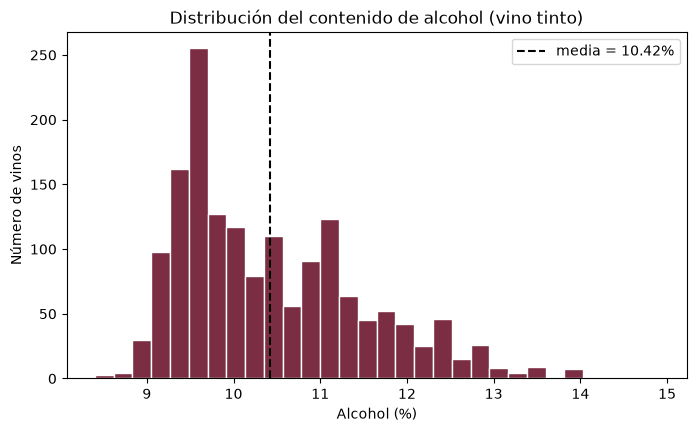

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(df["alcohol"], bins=30, color="#7b2d43", edgecolor="white")
ax.axvline(df["alcohol"].mean(), color="black", ls="--", label=f"media = {df['alcohol'].mean():.2f}%")
ax.set(title="Distribución del contenido de alcohol (vino tinto)", xlabel="Alcohol (%)", ylabel="Número de vinos")
ax.legend()
plt.show()

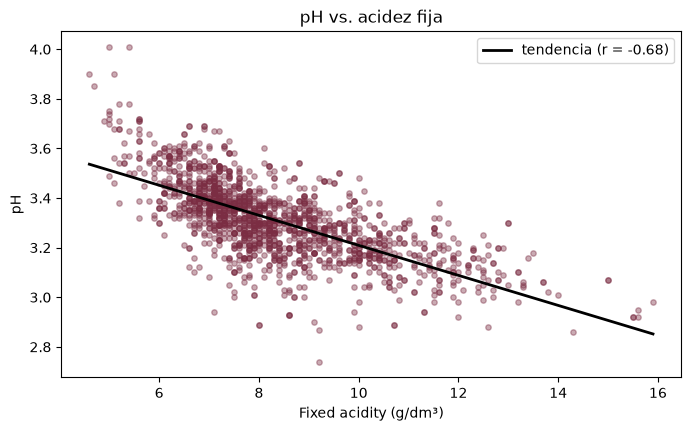

Coeficiente de correlación de Pearson: -0.683


In [10]:
x, y = df["fixed acidity"], df["pH"]
m, b = np.polyfit(x, y, 1)
r = np.corrcoef(x, y)[0, 1]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(x, y, alpha=0.4, s=15, color="#7b2d43")
xs = np.linspace(x.min(), x.max(), 100)
ax.plot(xs, m * xs + b, color="black", lw=2, label=f"tendencia (r = {r:.2f})")
ax.set(title="pH vs. acidez fija", xlabel="Fixed acidity (g/dm³)", ylabel="pH")
ax.legend()
plt.show()
print(f"Coeficiente de correlación de Pearson: {r:.3f}")

**¿Notas alguna tendencia?** Sí: la tendencia es **negativa** y bastante marcada (r ≈ −0.68). Cuanta más acidez fija tiene el vino, más bajo es su pH. Tiene sentido químico, porque el pH es una escala inversa de la concentración de ácido.

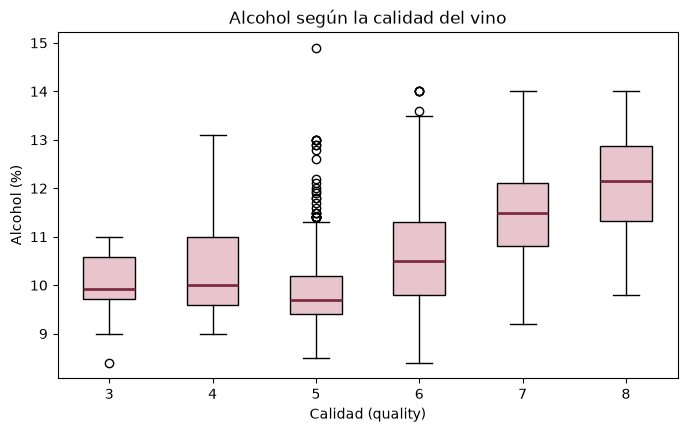

In [11]:
calidades = sorted(df["quality"].unique())
datos = [df.loc[df["quality"] == q, "alcohol"] for q in calidades]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.boxplot(datos, tick_labels=calidades, patch_artist=True,
           boxprops=dict(facecolor="#e8c4cc"), medianprops=dict(color="#7b2d43", lw=2))
ax.set(title="Alcohol según la calidad del vino", xlabel="Calidad (quality)", ylabel="Alcohol (%)")
plt.show()

**Observación:** de la calidad 5 en adelante, la mediana de alcohol sube con la calidad. Los vinos mejor calificados (7 y 8) suelen tener más alcohol, así que `alcohol` es una de las variables que mejor separan a los vinos "buenos".

---
# Ejercicio 2 — Palmer Penguins

## Ejercicio 2.1 — Análisis exploratorio con Pandas
**Nombre:** NOMBRE COMPLETO · **Matrícula:** MATRÍCULA

**Lógica:** cargo el CSV de pingüinos y cuento cuántas filas tienen al menos un `NaN` con `isnull().any(axis=1)`. Elimino solo las filas sin datos críticos (peso y medidas del pico) usando `dropna(subset=...)`. Con `groupby` saco la masa corporal promedio por especie y por isla. Al final filtro con dos condiciones: Gentoo **y** más de 5000 g.

In [12]:
url_ping = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv"
peng = pd.read_csv(url_ping)
print("Dataset cargado correctamente:", peng.shape)
peng.head()

Dataset cargado correctamente: (344, 7)


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


In [13]:
print("Nulos por columna:\n", peng.isnull().sum())
print("\nFilas con al menos un NaN:", peng.isnull().any(axis=1).sum())

criticas = ["body_mass_g", "bill_length_mm", "bill_depth_mm"]
peng = peng.dropna(subset=criticas).reset_index(drop=True)
print(f"Filas tras eliminar las que no tienen datos críticos: {len(peng)}")

Nulos por columna:
 species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
Length: 7, dtype: int64

Filas con al menos un NaN: 11
Filas tras eliminar las que no tienen datos críticos: 342


In [14]:
masa_promedio = peng.groupby(["species", "island"])["body_mass_g"].mean().round(1)
masa_promedio.to_frame("masa_promedio_g")

masa_promedio_g
species   island                    
Adelie    Biscoe              3709.7
          Dream               3688.4
          Torgersen           3706.4
Chinstrap Dream               3733.1
Gentoo    Biscoe              5076.0

[5 rows x 1 columns]

In [15]:
gentoo_pesados = peng[(peng["species"] == "Gentoo") & (peng["body_mass_g"] > 5000)]
print(f"Gentoo de más de 5000 g: {len(gentoo_pesados)}")
gentoo_pesados.head()

Gentoo de más de 5000 g: 61


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
220,Gentoo,Biscoe,50.0,16.3,230.0,5700.0,MALE
222,Gentoo,Biscoe,50.0,15.2,218.0,5700.0,MALE
223,Gentoo,Biscoe,47.6,14.5,215.0,5400.0,MALE
226,Gentoo,Biscoe,46.7,15.3,219.0,5200.0,MALE
228,Gentoo,Biscoe,46.8,15.4,215.0,5150.0,MALE


## Ejercicio 2.2 — Procesamiento de señales con NumPy
**Nombre:** NOMBRE COMPLETO · **Matrícula:** MATRÍCULA

**Lógica:** extraigo `bill_length_mm` y `bill_depth_mm` como una matriz de $n \times 2$, una fila por pingüino. La proporción largo/alto sale de dividir las dos columnas elemento a elemento. Para los *outliers*, `np.where` busca los pingüinos con $|x - \mu| > 2\sigma$ en el largo del pico. El *slicing* `[::2]` toma las posiciones pares (0, 2, 4, …).

In [16]:
pico = peng[["bill_length_mm", "bill_depth_mm"]].to_numpy()
print("Forma de la matriz:", pico.shape)
pico[:5]

Forma de la matriz: (342, 2)


array([[39.1, 18.7],
       [39.5, 17.4],
       [40.3, 18. ],
       [36.7, 19.3],
       [39.3, 20.6]])

In [17]:
proporcion = pico[:, 0] / pico[:, 1]
print("Primeras proporciones largo/alto:", np.round(proporcion[:5], 3))
print(f"Media: {proporcion.mean():.3f} | mín: {proporcion.min():.3f} | máx: {proporcion.max():.3f}")

Primeras proporciones largo/alto: [2.091 2.27  2.239 1.902 1.908]
Media: 2.606 | mín: 1.640 | máx: 3.613


In [18]:
largo = pico[:, 0]
mu_l, sd_l = np.mean(largo), np.std(largo)
idx_outliers = np.where(np.abs(largo - mu_l) > 2 * sd_l)[0]

print(f"Media del largo: {mu_l:.2f} mm | desv. estándar: {sd_l:.2f} mm")
print(f"Rango normal: [{mu_l - 2*sd_l:.2f}, {mu_l + 2*sd_l:.2f}] mm")
print(f"Pingüinos fuera de ±2σ: {len(idx_outliers)}")
peng.loc[idx_outliers, ["species", "island", "bill_length_mm"]]

Media del largo: 43.92 mm | desv. estándar: 5.45 mm
Rango normal: [33.02, 54.83] mm
Pingüinos fuera de ±2σ: 6


,species,island,bill_length_mm
141,Adelie,Dream,32.1
168,Chinstrap,Dream,58.0
214,Chinstrap,Dream,55.8
252,Gentoo,Biscoe,59.6
320,Gentoo,Biscoe,55.9
334,Gentoo,Biscoe,55.1


In [19]:
pares = pico[::2]
print(f"Original: {pico.shape} -> posiciones pares: {pares.shape}")
pares[:5]

Original: (342, 2) -> posiciones pares: (171, 2)


array([[39.1, 18.7],
       [40.3, 18. ],
       [39.3, 20.6],
       [39.2, 19.6],
       [42. , 20.2]])

## Ejercicio 2.3 — Visualización científica con Matplotlib
**Nombre:** NOMBRE COMPLETO · **Matrícula:** MATRÍCULA

**Lógica:** dibujo un scatter de `flipper_length_mm` contra `body_mass_g`, con una serie de color por especie para ver cómo se agrupan. Ubico al pingüino más pesado con `idxmax()` y lo señalo con `annotate` (flecha y texto). Al final armo una figura de 1×2 *subplots*: a la izquierda la masa corporal y a la derecha el tamaño de las aletas, en ambos casos por especie.

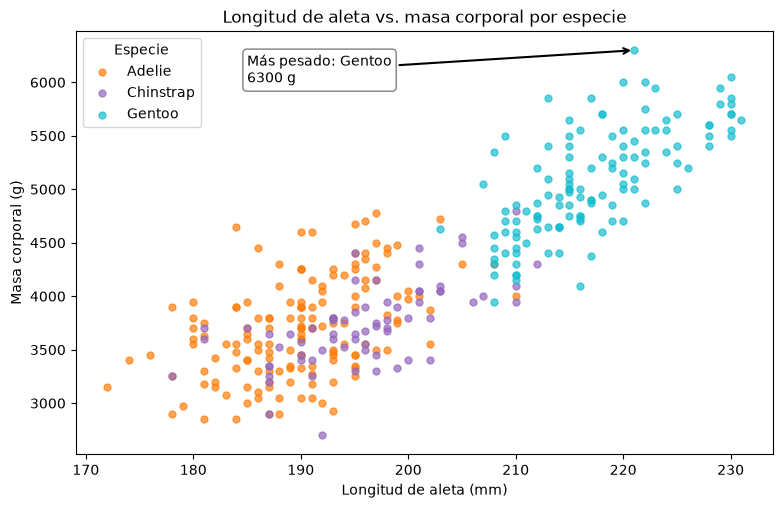

In [20]:
colores = {"Adelie": "#ff7f0e", "Chinstrap": "#9467bd", "Gentoo": "#17becf"}

fig, ax = plt.subplots(figsize=(9, 5.5))
for especie, grupo in peng.groupby("species"):
    ax.scatter(grupo["flipper_length_mm"], grupo["body_mass_g"],
               label=especie, color=colores[especie], alpha=0.7, s=25)

mas_pesado = peng.loc[peng["body_mass_g"].idxmax()]
ax.annotate(f"Más pesado: {mas_pesado['species']}\n{mas_pesado['body_mass_g']:.0f} g",
            xy=(mas_pesado["flipper_length_mm"], mas_pesado["body_mass_g"]),
            xytext=(185, 6000),
            arrowprops=dict(arrowstyle="->", color="black", lw=1.5),
            fontsize=10, bbox=dict(boxstyle="round", fc="white", ec="gray"))

ax.set(title="Longitud de aleta vs. masa corporal por especie",
       xlabel="Longitud de aleta (mm)", ylabel="Masa corporal (g)")
ax.legend(title="Especie")
plt.show()

**Observación:** los Gentoo forman un grupo claramente separado, con aletas más largas y más peso. Adelie y Chinstrap se enciman bastante en estas dos variables. En todas las especies hay una relación positiva: aleta más larga, mayor masa.

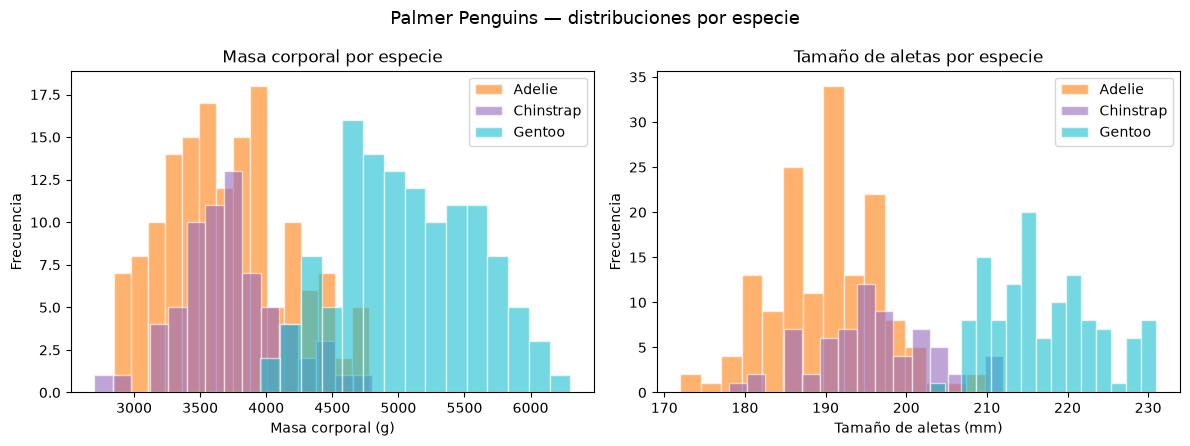

In [21]:
especies = list(colores)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

for ax, col, titulo, unidad in [(ax1, "body_mass_g", "Masa corporal", "g"),
                                (ax2, "flipper_length_mm", "Tamaño de aletas", "mm")]:
    for e in especies:
        ax.hist(peng.loc[peng["species"] == e, col], bins=15, alpha=0.6,
                color=colores[e], label=e, edgecolor="white")
    ax.set(title=f"{titulo} por especie", xlabel=f"{titulo} ({unidad})", ylabel="Frecuencia")
    ax.legend()

fig.suptitle("Palmer Penguins — distribuciones por especie", fontsize=13)
plt.tight_layout()
plt.show()

---
## Conclusión
- **Pandas** sirvió para cargar, limpiar (nulos), crear variables (`is_good`), agrupar y filtrar con condiciones compuestas.
- **NumPy** sirvió para los cálculos vectorizados: estadísticos por columna, normalización Z-score manual, proporciones, detección de *outliers* con ±2σ y *slicing*.
- **Matplotlib** dejó ver las relaciones: alcohol ↔ calidad y acidez ↔ pH en los vinos, y una separación natural de los Gentoo en los pingüinos.